# Percentage-error comparison

This notebook reads the four final prediction files produced by the fixed workflows, validates their timestamps and actual targets, and generates the FCNN and LSTM percentage-error figures at 600 dpi. It also creates an enhanced two-panel version that combines the first-300-sample signed errors with the full-test empirical distribution of absolute percentage error.

Please cite the following paper when you use or reference this code
Oluwafolajimi Samuel Bolusteve, Linhan Fang, and Xingpeng Li, “Net Load Forecasting with Renewable Capacity Features: A Comparison of Direct and Indirect Neural Network Methods”, IEEE Texas Power and Energy Conference, College Station, TX, USA, Feb. 2027.

## 1. Imports and repository paths

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 9,
    "axes.labelsize": 10,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})

def find_project_root():
    """Find the GitHub release root from either the repository or the paper Results folder."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidates = [
            base,
            base / "GitHub Code Release",
            base / "Final Code" / "GitHub Code Release",
        ]
        for candidate in candidates:
            if (candidate / "Data Download").is_dir() and (candidate / "FCNN Direct Method").is_dir():
                return candidate
    raise FileNotFoundError(
        "Cannot locate the repository root containing 'Data Download' and the method folders."
    )

PROJECT_ROOT = find_project_root()
OUTPUT_DIR = PROJECT_ROOT / "fixed_outputs"
FIGURE_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "Results"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
TIME_COLUMN = "time"
FIRST_N = 300
MAPE_MIN_ACTUAL_MW = 1.0


## 2. Read and validate the four fixed prediction files

In [2]:
prediction_files = {
    "FCNN Direct": "fcnn_direct_net_load_predictions.csv",
    "FCNN Indirect": "fcnn_indirect_net_load_predictions.csv",
    "LSTM Direct": "lstm_direct_net_load_predictions.csv",
    "LSTM Indirect": "lstm_indirect_net_load_predictions.csv",
}

def read_prediction(filename, model_name):
    path = OUTPUT_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {model_name} prediction file: {path}. "
            "Run the corresponding fixed workflow first."
        )
    frame = pd.read_csv(path, usecols=[TIME_COLUMN, "actual", "predict"], parse_dates=[TIME_COLUMN])
    if frame[TIME_COLUMN].duplicated().any():
        raise ValueError(f"{model_name} contains duplicate timestamps.")
    if frame[["actual", "predict"]].isna().any().any():
        raise ValueError(f"{model_name} contains missing actual or predicted values.")
    return frame.sort_values(TIME_COLUMN).reset_index(drop=True)

prediction_frames = {
    model_name: read_prediction(filename, model_name)
    for model_name, filename in prediction_files.items()
}

reference_name = "FCNN Direct"
reference = prediction_frames[reference_name]
for model_name, frame in prediction_frames.items():
    if not frame[TIME_COLUMN].equals(reference[TIME_COLUMN]):
        raise ValueError(f"{model_name} does not use the same test timestamps as {reference_name}.")
    if not np.allclose(frame["actual"], reference["actual"], rtol=0.0, atol=1e-6):
        raise ValueError(f"{model_name} does not use the same actual net-load target.")

comparison = reference[[TIME_COLUMN, "actual"]].copy()
for model_name, frame in prediction_frames.items():
    column_name = model_name.lower().replace(" ", "_")
    comparison[column_name] = frame["predict"].to_numpy()

print("Validated common test timestamps:", len(comparison))
print("Test interval:", comparison[TIME_COLUMN].min(), "to", comparison[TIME_COLUMN].max())
comparison.head()


Validated common test timestamps: 1754
Test interval: 2024-10-20 05:00:00 to 2025-01-01 06:00:00


,time,actual,fcnn_direct,fcnn_indirect,lstm_direct,lstm_indirect
0,2024-10-20 05:00:00,25361.962786,27160.164,26756.265503,25319.602,25217.224609
1,2024-10-20 06:00:00,23383.175588,26828.225,26461.319946,23505.826,23700.472656
2,2024-10-20 07:00:00,22096.136331,25919.988,26301.692505,22330.145,22354.101562
3,2024-10-20 08:00:00,21250.184987,24420.395,25363.952026,21323.945,21488.119141
4,2024-10-20 09:00:00,21563.937474,24607.037,25147.311646,20937.168,21092.767578


## 3. Signed percentage errors and Table IV statistics

In [3]:
percentage_errors = {}
statistics_rows = []
mape_mask = comparison["actual"].abs() > MAPE_MIN_ACTUAL_MW
if not mape_mask.all():
    print(f"MAPE excludes {(~mape_mask).sum()} samples at or below {MAPE_MIN_ACTUAL_MW} MW.")

for model_name in prediction_files:
    prediction_column = model_name.lower().replace(" ", "_")
    signed_error = 100.0 * (comparison[prediction_column] - comparison["actual"]) / comparison["actual"]
    percentage_errors[model_name] = signed_error
    ape = signed_error.loc[mape_mask].abs()
    statistics_rows.append({
        "Method Name": model_name,
        "Max (%)": ape.max(),
        "Min (%)": ape.min(),
        "MAPE (%)": ape.mean(),
        "Median (%)": ape.median(),
        "Std Dev (%)": ape.std(ddof=1),
        "RMSPE (%)": np.sqrt(np.mean(signed_error.loc[mape_mask] ** 2)),
    })

ape_statistics = pd.DataFrame(statistics_rows)
ape_statistics.to_csv(RESULTS_DIR / "Table_IV_APE_Statistics.csv", index=False)
ape_statistics.to_excel(RESULTS_DIR / "Table_IV_APE_Statistics.xlsx", index=False)
ape_statistics.round(3)


,Method Name,Max (%),Min (%),MAPE (%),Median (%),Std Dev (%),RMSPE (%)
0,FCNN Direct,40.866,0.000,7.138,5.353,6.263,9.495
1,FCNN Indirect,63.766,0.021,7.398,5.851,6.433,9.803
2,LSTM Direct,28.636,0.003,2.730,2.008,2.690,3.832
3,LSTM Indirect,32.083,0.001,2.464,1.831,2.605,3.585


## 4. Reusable publication-figure functions

In [4]:
def save_percentage_error_figure(model_names, colors, filename):
    """Save the paper-compatible first-300-sample signed-error figure."""
    sample_count = min(FIRST_N, len(comparison))
    sample_index = np.arange(sample_count)
    fig, ax = plt.subplots(figsize=(5.5, 2.7))
    for model_name, color in zip(model_names, colors):
        ax.plot(
            sample_index, percentage_errors[model_name].iloc[:sample_count],
            label=model_name, color=color, linewidth=0.9, alpha=0.9,
        )
    ax.axhline(0.0, color="black", linewidth=1.0, alpha=0.8)
    ax.set_xlabel("Sample Index")
    ax.set_ylabel("Percentage Error (%)")
    ax.set_xticks(range(0, sample_count + 1, 50))
    ax.grid(True, linestyle="--", linewidth=0.55, color="#bfbfbf", alpha=0.65)
    ax.legend(loc="upper right", frameon=True, fancybox=False, edgecolor="#bfbfbf", framealpha=1.0)
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.0)
    ax.tick_params(direction="out", length=3.0, width=0.8, colors="black")
    fig.tight_layout(pad=0.5)
    output_path = FIGURE_DIR / filename
    fig.savefig(output_path, dpi=600, bbox_inches="tight")
    print("Saved figure:", output_path)
    plt.show()
    plt.close(fig)

def save_enhanced_error_figure(model_names, colors, filename):
    """Combine local signed errors with the full-test APE empirical CDF."""
    sample_count = min(FIRST_N, len(comparison))
    sample_index = np.arange(sample_count)
    fig, (ax_error, ax_ecdf) = plt.subplots(
        2, 1, figsize=(5.5, 5.2), gridspec_kw={"height_ratios": [1.35, 1.0]}
    )
    for model_name, color in zip(model_names, colors):
        signed_error = percentage_errors[model_name]
        ape = np.sort(signed_error.loc[mape_mask].abs().to_numpy())
        ecdf = 100.0 * np.arange(1, len(ape) + 1) / len(ape)
        ax_error.plot(
            sample_index, signed_error.iloc[:sample_count],
            label=model_name, color=color, linewidth=0.85, alpha=0.88,
        )
        ax_ecdf.plot(
            ape, ecdf, color=color, linewidth=1.25,
            label=f"{model_name} (MAPE={ape.mean():.2f}%)",
        )
    ax_error.axhline(0.0, color="black", linewidth=1.0, alpha=0.8)
    ax_error.set_ylabel("Signed error (%)")
    ax_error.set_xticks(range(0, sample_count + 1, 50))
    ax_error.grid(True, linestyle="--", linewidth=0.55, color="#bfbfbf", alpha=0.65)
    ax_error.legend(loc="upper right", frameon=True, fancybox=False, edgecolor="#bfbfbf", framealpha=1.0)
    ax_error.text(0.01, 0.95, "(a) First 300 test samples", transform=ax_error.transAxes, va="top", bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1.0})
    ax_ecdf.set_xlabel("Absolute percentage error (%)")
    ax_ecdf.set_ylabel("Empirical CDF (%)")
    ax_ecdf.set_xlim(left=0.0)
    ax_ecdf.set_ylim(0.0, 102.0)
    ax_ecdf.grid(True, linestyle="--", linewidth=0.55, color="#bfbfbf", alpha=0.65)
    ax_ecdf.legend(loc="lower right", frameon=True, fancybox=False, edgecolor="#bfbfbf", framealpha=1.0)
    ax_ecdf.text(0.01, 0.90, "(b) Full common test set", transform=ax_ecdf.transAxes, va="top", bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1.0})
    for ax in (ax_error, ax_ecdf):
        for spine in ax.spines.values():
            spine.set_color("black")
            spine.set_linewidth(1.0)
        ax.tick_params(direction="out", length=3.0, width=0.8, colors="black")
    fig.tight_layout(pad=0.5)
    output_path = FIGURE_DIR / filename
    fig.savefig(output_path, dpi=600, bbox_inches="tight")
    print("Saved enhanced figure:", output_path)
    plt.show()
    plt.close(fig)


## 5. Figure 8: FCNN direct and indirect percentage errors

Saved figure: C:\Users\lfang7\Project\Report\Conference paper\2026 TPEC\GitHub Code Release\GitHub Code Release\figures\Fig_8_FCNN_Percentage_Error.png


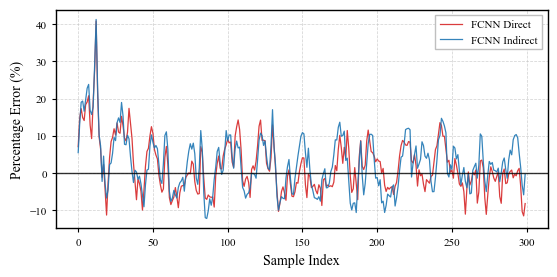

Saved enhanced figure: C:\Users\lfang7\Project\Report\Conference paper\2026 TPEC\GitHub Code Release\GitHub Code Release\figures\Fig_8_FCNN_Percentage_Error_Enhanced.png


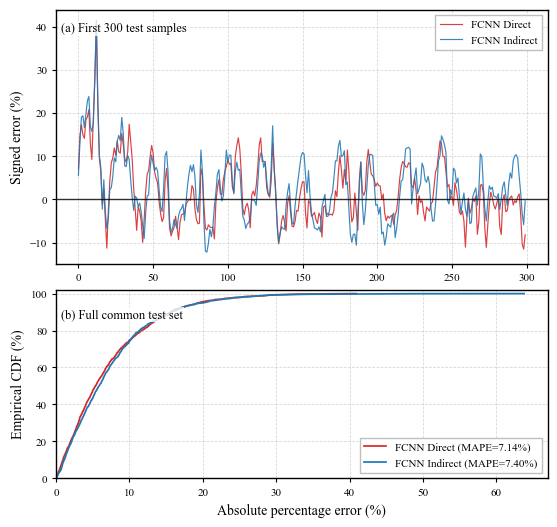

In [5]:
fcnn_models = ["FCNN Direct", "FCNN Indirect"]
fcnn_colors = ["#d62728", "#1f77b4"]
save_percentage_error_figure(
    fcnn_models, fcnn_colors, "Fig_8_FCNN_Percentage_Error.png"
)
save_enhanced_error_figure(
    fcnn_models, fcnn_colors, "Fig_8_FCNN_Percentage_Error_Enhanced.png"
)


## 6. Figure 12: LSTM direct and indirect percentage errors

Saved figure: C:\Users\lfang7\Project\Report\Conference paper\2026 TPEC\GitHub Code Release\GitHub Code Release\figures\Fig_12_LSTM_Percentage_Error.png


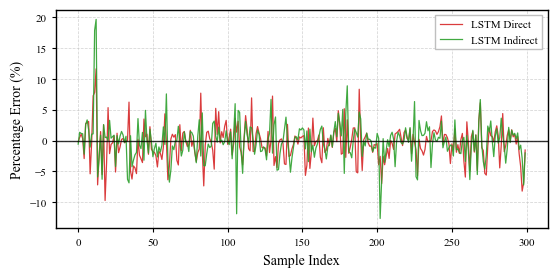

Saved enhanced figure: C:\Users\lfang7\Project\Report\Conference paper\2026 TPEC\GitHub Code Release\GitHub Code Release\figures\Fig_12_LSTM_Percentage_Error_Enhanced.png


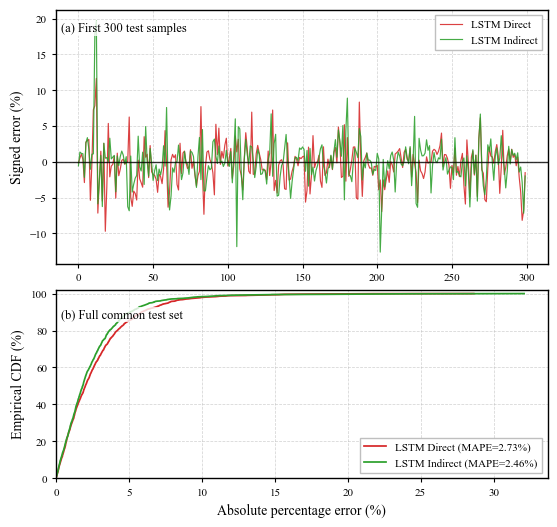

In [6]:
lstm_models = ["LSTM Direct", "LSTM Indirect"]
lstm_colors = ["#d62728", "#2ca02c"]
save_percentage_error_figure(
    lstm_models, lstm_colors, "Fig_12_LSTM_Percentage_Error.png"
)
save_enhanced_error_figure(
    lstm_models, lstm_colors, "Fig_12_LSTM_Percentage_Error_Enhanced.png"
)
